# Week 11 · Lecture 2
## Risk, state-dependent interest rates, and bond prices

**Required reading:** [QuantEcon, Asset Pricing: Finite State Models](https://python.quantecon.org/markov_asset.html).  
**Learning objectives:** interpret risk aversion and persistence experiments; price one-period risk-free claims; compute state-dependent risk-free returns; price a consol and compare its cash flows with a Lucas tree; distinguish risk-neutral and marginal-utility pricing.

**Roadmap (75 minutes):** 10 min review; 15 min risk aversion; 10 min persistence; 15 min risk-free bonds; 15 min consols; 10 min risk premia and synthesis.

We use the **same illustrative three-state economy as Lecture 1 and the problem set**.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

states = ["Recession", "Normal", "Expansion"]
P = np.array([[0.80, 0.15, 0.05],
              [0.10, 0.80, 0.10],
              [0.05, 0.15, 0.80]])
g = np.array([0.98, 1.02, 1.06])
beta, gamma = 0.95, 2.0

def lucas_pd(P, g, beta, gamma):
    B = beta * P * g[np.newaxis, :]**(1-gamma)
    if max(abs(np.linalg.eigvals(B))) >= 1:
        raise ValueError('Pricing operator does not have a finite fundamental solution')
    return np.linalg.solve(np.eye(len(g))-B, B @ np.ones(len(g)))

v = lucas_pd(P, g, beta, gamma)
print('Baseline P/D:', dict(zip(states, np.round(v, 5))))

Baseline P/D: {'Recession': np.float64(15.61912), 'Normal': np.float64(14.10851), 'Expansion': np.float64(12.83747)}


## 1. Review: prices are discounted marginal-utility-weighted payoffs

For any asset with next-period payoff $x_{t+1}$,

$$p_t=\mathbb E_t[m_{t+1}x_{t+1}],\qquad m_{t+1}=\beta g_{s_{t+1}}^{-\gamma}.$$

For the Lucas tree, $x_{t+1}=d_{t+1}+p_{t+1}$. If $p_t=v_{s_t}d_t$, then

$$v_i=\beta\sum_jP_{ij}g_j^{1-\gamma}(1+v_j).$$

Today we keep the same discount factor but change preferences, transition probabilities, and payoff structures.

## 2. Experiment: how does risk aversion change Lucas tree prices?

Holding $P$, $g$, and $\beta$ fixed, vary $\gamma$. Higher $\gamma$ increases the weight on payoffs received in low-consumption-growth states. But a change in $\gamma$ need **not** lower every asset price: it changes both discounting and how future dividends covary with marginal utility. The direction is a quantitative question.

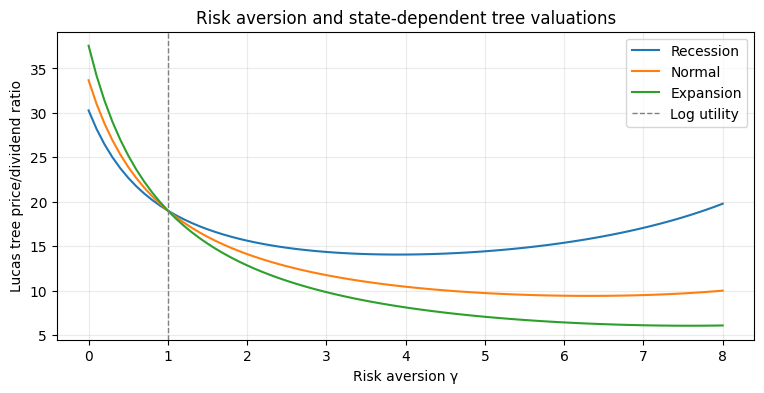

At gamma=1 all P/D ratios: [19. 19. 19.]


In [2]:
gammas = np.linspace(0, 8, 81)
values = np.array([lucas_pd(P, g, beta, x) for x in gammas])
fig, ax = plt.subplots(figsize=(9, 4))
for j, state in enumerate(states):
    ax.plot(gammas, values[:, j], label=state)
ax.axvline(1, linestyle='--', color='gray', linewidth=1, label='Log utility')
ax.set(xlabel='Risk aversion γ', ylabel='Lucas tree price/dividend ratio',
       title='Risk aversion and state-dependent tree valuations')
ax.legend(); ax.grid(alpha=.25)
plt.show()
print('At gamma=1 all P/D ratios:', values[10])

**Interpretation prompt:** Compare prices across current states. Current state matters through the row $P_{i\cdot}$, which determines the distribution of next-period growth. Identify which states forecast relatively low future growth and explain how that affects marginal-utility discounting.

## 3. Experiment: change persistence without changing the growth states

Construct $P(\lambda)=\lambda I+(1-\lambda)\mathbf 1\pi^\top$, where $\pi$ is the stationary distribution of the baseline chain and $0\le\lambda<1$. This family has **the same stationary distribution** for every $\lambda$ but increasingly persistent states. It isolates persistence from long-run state frequencies.

For a clean comparison, first compute $\pi$ from the original $P$; the family $P(\lambda)$ need not reproduce the original transition matrix for any $\lambda$.

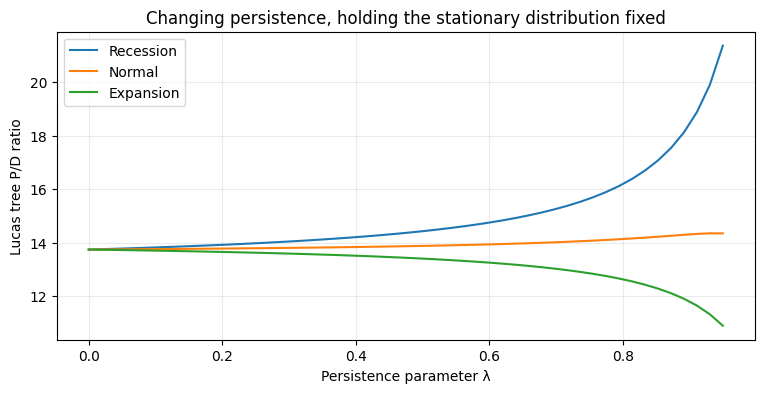

In [3]:
A = P.T - np.eye(len(g)); A[-1] = 1
rhs = np.zeros(len(g)); rhs[-1] = 1
pi = np.linalg.solve(A, rhs)
lam_grid = np.linspace(0, .95, 50)
prices_persistence = []
for lam in lam_grid:
    P_lam = lam*np.eye(len(g)) + (1-lam)*np.outer(np.ones(len(g)), pi)
    prices_persistence.append(lucas_pd(P_lam, g, beta, gamma))
prices_persistence = np.array(prices_persistence)
fig, ax = plt.subplots(figsize=(9, 4))
for j, state in enumerate(states):
    ax.plot(lam_grid, prices_persistence[:,j], label=state)
ax.set(xlabel='Persistence parameter λ', ylabel='Lucas tree P/D ratio',
       title='Changing persistence, holding the stationary distribution fixed')
ax.legend(); ax.grid(alpha=.25)
plt.show()

## 4. One-period risk-free bonds

A one-period risk-free claim pays **one unit of consumption next period in every state**. Its current state-$i$ price is

$$\boxed{q_i=\mathbb E_i[m_{t+1}]=\beta\sum_jP_{ij}g_j^{-\gamma}.}$$

Its gross risk-free return is known today:

$$\boxed{R_{f,i}=\frac{1}{q_i}.}$$

The bond payoff is certain, but its **price can depend on the current state** because the distribution of future marginal utility changes with $i$. A risk-free bond is not necessarily a constant-price bond.

Recession  q=0.970578, gross Rf=1.030314, net rate=3.031%
Normal     q=0.913955, gross Rf=1.094146, net rate=9.415%
Expansion  q=0.862822, gross Rf=1.158987, net rate=15.899%


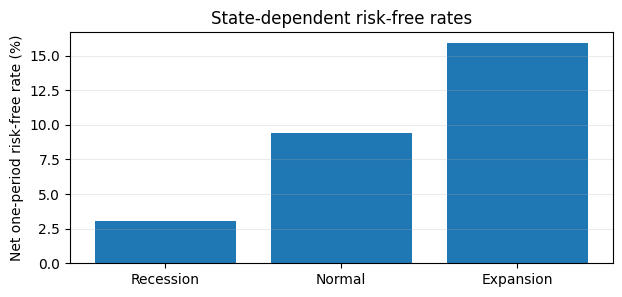

In [4]:
q = beta * (P @ (g**(-gamma)))
Rf = 1 / q
for i, name in enumerate(states):
    print(f'{name:10s} q={q[i]:.6f}, gross Rf={Rf[i]:.6f}, net rate={100*(Rf[i]-1):.3f}%')

fig, ax = plt.subplots(figsize=(7, 3))
ax.bar(states, 100*(Rf-1))
ax.set(ylabel='Net one-period risk-free rate (%)', title='State-dependent risk-free rates')
ax.grid(axis='y', alpha=.25)
plt.show()

### Why the bond is different from the tree

For a **fixed payoff of one**, only the SDF contributes a growth term $g_j^{-\gamma}$. For the **Lucas tree**, next period's payoff is proportional to the growing endowment, producing $g_j^{1-\gamma}$.

This distinction is crucial: it explains why the tree and bond have different pricing matrices.

## 5. Consol bonds: an infinite stream of fixed coupons

Consider an ex-coupon consol that pays one unit of consumption **next period and every period thereafter**. Let $b_i$ be its ex-coupon price when the current state is $i$. Next period, the investor receives the coupon $1$ plus the resale value $b_j$.

$$b_i=\beta\sum_jP_{ij}g_j^{-\gamma}(1+b_j).$$

Define $M_{ij}=\beta P_{ij}g_j^{-\gamma}$. Then

$$b=M(\mathbf 1+b),\qquad \boxed{b=(I-M)^{-1}M\mathbf 1}.$$

The inverse formula requires $\rho(M)<1$. A consol is an infinite stream of **fixed real coupons**; the Lucas tree is an infinite stream of **growing dividends**.

In [5]:
M = beta * P * g[np.newaxis, :]**(-gamma)
radius = max(abs(np.linalg.eigvals(M)))
print('Consol pricing spectral radius:', radius)
assert radius < 1
b_consol = np.linalg.solve(np.eye(len(g))-M, M @ np.ones(len(g)))
for name, tree, consol in zip(states, v, b_consol):
    print(f'{name:10s}: tree P/D={tree:10.5f}; consol price={consol:10.5f}')
assert np.allclose(b_consol, M @ (1+b_consol))

Consol pricing spectral radius: 0.9250597984299738
Recession : tree P/D=  15.61912; consol price=  14.34985
Normal    : tree P/D=  14.10851; consol price=  11.74141
Expansion : tree P/D=  12.83747; consol price=   9.82911


## 6. Risk-neutral pricing versus consumption-based pricing

If $\gamma=0$, marginal utility is constant and $m_{t+1}=\beta$. The pricing equation becomes

$$p_t=\beta\mathbb E_t[p_{t+1}+d_{t+1}].$$

This is **risk-neutral preference pricing** with a constant discount factor. It is distinct from a change of probability measure under a risk-neutral pricing representation for risk-averse agents.

For the one-period fixed-payoff bond, $q_i=\beta$ and $R_{f,i}=1/\beta$ in every state. For the Lucas tree, growth still matters because the dividend payoff changes with the state.

In [6]:
for risk_aversion in [0, 1, 2, 5]:
    tree = lucas_pd(P, g, beta, risk_aversion)
    bond_q = beta * P @ (g**(-risk_aversion))
    print(f'gamma={risk_aversion}: tree P/D={np.round(tree,3)}, Rf={np.round(1/bond_q,4)}')

gamma=0: tree P/D=[30.271 33.67  37.554], Rf=[1.0526 1.0526 1.0526]
gamma=1: tree P/D=[19. 19. 19.], Rf=[1.0416 1.0734 1.1048]
gamma=2: tree P/D=[15.619 14.109 12.837], Rf=[1.0303 1.0941 1.159 ]
gamma=5: tree P/D=[14.423  9.725  7.055], Rf=[0.9947 1.1568 1.3342]


## 7. Risk premia and the covariance interpretation

For any asset with gross return $R_{t+1}$, the normalized pricing equation is

$$1=\mathbb E_t[m_{t+1}R_{t+1}].$$

Using $\mathbb E_t[m_{t+1}]=1/R_{f,t}$,

$$\boxed{\mathbb E_t[R_{t+1}]-R_{f,t}=-R_{f,t}\operatorname{Cov}_t(m_{t+1},R_{t+1}).}$$

An asset that tends to pay high returns when marginal utility is **low** has negative covariance with the SDF and generally requires a positive expected excess return. This is the consumption-risk interpretation of a risk premium.

For the Lucas tree, the gross return from state $i$ to next state $j$ is

$$R^{\mathrm{tree}}_{ij}=\frac{g_j(1+v_j)}{v_i}.$$

In [7]:
tree_returns = g[np.newaxis,:] * (1+v)[np.newaxis,:] / v[:,np.newaxis]
expected_tree_returns = np.sum(P * tree_returns, axis=1)
excess = expected_tree_returns - Rf
sdf = beta * g**(-gamma)
for i, name in enumerate(states):
    cov = np.sum(P[i] * (sdf-q[i]) * (tree_returns[i]-expected_tree_returns[i]))
    print(f'{name:10s}: E[Rtree]={expected_tree_returns[i]:.6f}, '
          f'Rf={Rf[i]:.6f}, excess={excess[i]:+.6f}, '
          f'-Rf*Cov={-Rf[i]*cov:+.6f}')
    assert np.isclose(excess[i], -Rf[i]*cov)

Recession : E[Rtree]=1.029147, Rf=1.030314, excess=-0.001166, -Rf*Cov=-0.001166
Normal    : E[Rtree]=1.093240, Rf=1.094146, excess=-0.000905, -Rf*Cov=-0.000905
Expansion : E[Rtree]=1.157558, Rf=1.158987, excess=-0.001429, -Rf*Cov=-0.001429


## 8. Synthesis, discussion, and optional extension

**What students should now be able to explain:**

1. Why is a risk-free asset's price state-dependent even though its payoff is not?
2. Why does the Lucas tree matrix contain $g^{1-\gamma}$, while the consol matrix contains $g^{-\gamma}$?
3. How does increasing Markov persistence change the conditional distribution of future growth?
4. Why can changing risk aversion have different price effects across states?
5. Why does a negative covariance between an asset's return and the SDF imply a positive expected risk premium?

**Optional preview: American options.** An option adds a choice between exercise and continuation. Its value satisfies an optimal-stopping Bellman equation, such as $h_i=\max\{\text{exercise payoff}_i,\sum_j M_{ij}h_j\}$. Unlike the Lucas tree and consol problems, this equation includes a maximum and is generally nonlinear.

**Connection to the problem set:** Problems 4–5, with Problem 6 as a synthesis.